# Note before starting:

This *Tutorial directory* is intended as a continuation of the initial five notebooks (in the parent directory). Accordingly, it is assumed that you have already created an IBM Quantum account and successfully connected it to Qiskit. If this is not yet the case, please refer to the [Introduction notebook](../introduction.ipynb) for step-by-step setup instructions. While completing that setup is sufficient for execution, it is strongly recommended that you have worked through all five preceding notebooks, as the concepts covered there will be essential—and assessed—throughout this section.

In [18]:
import numpy as np, matplotlib.pyplot as plt
plt.style.use(['science', 'notebook', 'grid', 'dark_background'])

# OTHER QISKIT IMPORTS

from qiskit import *
from qiskit.visualization import *
from qiskit_ibm_runtime import *
from qiskit_aer import *

from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp

import time
from matplotlib import ticker

# DRAW STYLE (default mpl dark), check https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits and 
# https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.circuit_drawer for more styles

def draw_circuit(qc):
    return qc.draw(output = 'mpl', style = 'iqp-dark')

The *Clauser-Horne-Shimony-Holt* (CHSH) inequality is a fundamental result in quantum mechanics that provides a way to test the predictions of quantum mechanics against those of classical physics, specifically **local hidden variable theories** (which basically mean theories that assume the existence of hidden variables that determine the outcomes of measurements). Experimental verification of the inequality being violated is seen as confirmation that nature cannot be described by such theories.

As expected, this inequality is *routinely* violated by modern quantum experiments, which is a strong indication that the world is indeed non-local and that quantum mechanics provides a more accurate description of reality than classical physics.

If we define a value in terms of correlation expectation values $\mathscr E(\cdot,\cdot)$ as $S = \mathscr E(a, b)\mp\big[\mathscr E(a, b') + \mathscr E(a', b)\big] + \mathscr E(a', b')$, where $a$ and $a'$ are two different measurement settings for one particle, and $b$ and $b'$ are two different measurement settings for the other particle, then the CHSH inequality simply states that $|S| \leq 2$ for any local hidden variable framework.

Quantum mechanics predicts that $|S|$ can exceed 2, with a maximum value of $2\sqrt{2}$, which is known as the *Tsirelson's bound.* This is precisely the case of the MES $\ket{\Phi^+}$ (this can be proven by direct calculation of the correlation expectation values for the appropriate measurement settings, try it out!) This is all for the introduction, let's see how to implement this in Qiskit!

# Implementation:

First, we have to create an entangled pair of qubits representing particles, on which we measure in different bases. Each observable is coded either a $+1$ or a $-1$, depending on the measurement outcome. Say a polarizer detects (+) and does not detect (-) the particle, then we can assign $+1$ to the former and $-1$ to the latter.

Hence, we have for both bases, 
1. $S_1 = \mathscr E(a, b) - \mathscr E(a, b') + \mathscr E(a', b) + \mathscr E(a', b')$
2. $S_2 = \mathscr E(a, b) - \mathscr E(a', b) + \mathscr E(a, b') + \mathscr E(a', b')$

Let's prepare $\ket{\Phi^+}$ and prepare the measurement settings for both bases, and then calculate $S_1$ and $S_2$. 

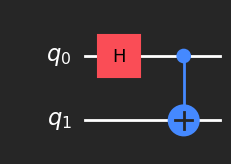

In [19]:
chsh = QuantumCircuit(2)

chsh.h(0)
chsh.cx(0, 1)

draw_circuit(chsh)

Let's measure $q_1$ in the $Z$ and $X$ bases and $q_0$ with respect to an angle $\theta\in[0,2\pi)$ in the $XZ$ plane. 
(Note: the choice of 50 + 1 phases is taken to balance between resolution and computational efficiency. Computation time is logged to be around 293 seconds on ibm_fez.)

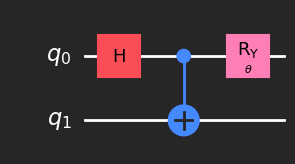

In [ ]:
theta = Parameter('$\\theta$')
chsh.ry(theta, 0)

phases = np.linspace(0, 2 * np.pi, 50 + 1) 
individual_phases = [[ph] for ph in phases]

draw_circuit(chsh)

Now to construct $S_i$:
- $S_1 = \langle ab \rangle - \langle ab' \rangle + \langle a'b \rangle + \langle a'b' \rangle \to \langle ZZ \rangle - \langle ZX \rangle + \langle XZ \rangle + \langle XX \rangle$
- $S_2 = \langle ab \rangle - \langle a'b \rangle + \langle ab' \rangle + \langle a'b' \rangle \to \langle ZZ \rangle - \langle XZ \rangle + \langle ZX \rangle + \langle XX \rangle$

Note that ZZ is shorthand for $Z \otimes Z$, and so on.

In [ ]:
S1 = SparsePauliOp.from_list(
    [('ZZ', 1), ('ZX', -1), ('XZ', 1), ('XX', 1)]
)

S2 = SparsePauliOp.from_list(
    [('ZZ', 1), ('ZX', 1), ('XZ', -1), ('XX', 1)]
)

print('S1:', S1)
print('S2:', S2)

S1: SparsePauliOp(['ZZ', 'ZX', 'XZ', 'XX'],
              coeffs=[ 1.+0.j, -1.+0.j,  1.+0.j,  1.+0.j])
S2: SparsePauliOp(['ZZ', 'ZX', 'XZ', 'XX'],
              coeffs=[ 1.+0.j,  1.+0.j, -1.+0.j,  1.+0.j])


The following codeblock will return the appropriate backend and your instance details. If it fails, make sure to follow the instructions in the [Introduction notebook](../introduction.ipynb) to set up your account and connect it to Qiskit. It's global across all notebooks, so you only have to do it once.

In [22]:
service = QiskitRuntimeService(channel = 'ibm_cloud')
backend = service.least_busy(simulator = False, operational = True)

backend.name, backend.num_qubits

('ibm_fez', 156)

In [23]:
print(service.instances())

[{'crn': 'crn:v1:bluemix:public:quantum-computing:us-east:a/a23b3ad5cbea449e928534b2015d2561:4e27099a-3e5a-4eb0-a31f-1bbc4bb84f3d::', 'plan': 'open', 'name': 'qiskit-global-instance', 'tags': [], 'pricing_type': 'free'}]


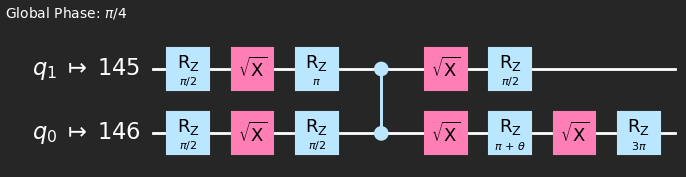

In [24]:
target = backend.target
pm = generate_preset_pass_manager(target = target, optimization_level = 3)

chsh_isa = pm.run(chsh)
draw_circuit(chsh_isa)

In [25]:
S1_isa = S1.apply_layout(chsh_isa.layout)
S2_isa = S2.apply_layout(chsh_isa.layout)

Now to initialize the `Estimator` and run the circuits::

In [ ]:
estimator = Estimator(mode = backend)
start_time = time.time()

pub = (
    chsh_isa,  # ISA circuit
    [[S1_isa], [S2_isa]],  # ISA Observables
    individual_phases,  # Parameter values
)

job_result = estimator.run(pubs = [pub]).result()
end_time = time.time()
elapsed_time = end_time - start_time

print(f'Elapsed time for job execution: {elapsed_time:.2f} seconds')

Elapsed time for job execution: 528.30 seconds


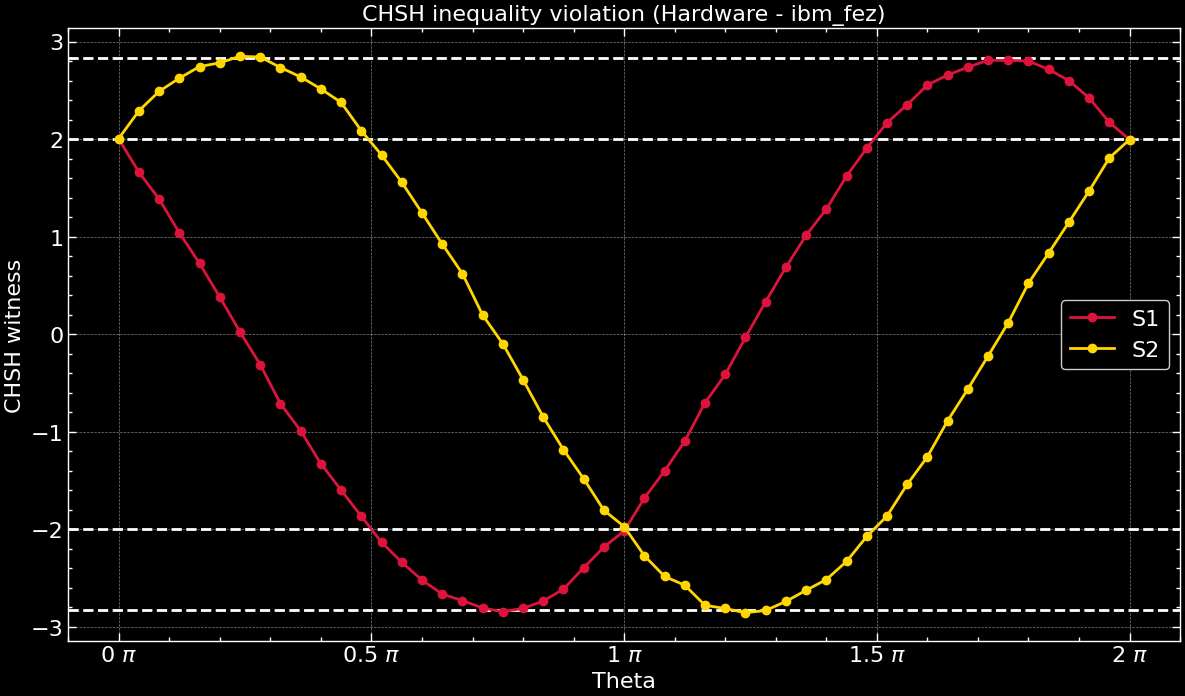

In [ ]:
ev1 = job_result[0].data.evs[0]
ev2 = job_result[0].data.evs[1]

fig, ax = plt.subplots(figsize = (12, 6.75))
plt.tight_layout()

# Results from hardware
ax.plot(phases / np.pi, ev1, 'o-', color = 'crimson',  label = 'S1', zorder = 3)
ax.plot(phases / np.pi, ev2, 'o-', color = 'gold', label = 'S2', zorder = 3)

# Classical bound (+-2)
ax.axhline(y = 2, color = '1', linestyle = '--')
ax.axhline(y = -2, color = '1', linestyle = '--')

# Quantum bound (+-2*sqrt(2))
ax.axhline(y = 2 * np.sqrt(2), color = '1', linestyle = '--')
ax.axhline(y = -2 * np.sqrt(2), color = '1', linestyle = '--')

ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%g $\\pi$'))
ax.xaxis.set_major_locator(ticker.MultipleLocator(base = 0.5))

plt.xlabel('Theta')
plt.ylabel('CHSH witness')
plt.title('CHSH inequality violation (Hardware - {})'.format(backend.name))
plt.legend()
plt.show()

It might be alarming to see that $S_i$ are exceeding the Tsirelson's bound at some points, but this is because this bound applies only to the CHSH **combination** of correlation expectation values, and not to the individual correlation expectation values themselves. As a sanity check, we can check the eigenvalues of the CHSH operator, which is defined as $CHSH = Z \otimes Z - Z \otimes X + X \otimes Z + X \otimes X$ (for $S_2$, the only difference is the sign of the second term). The maximum eigenvalue should be $2\sqrt{2}$, which is the Tsirelson's bound.

In [ ]:
CHSH = SparsePauliOp.from_list([
    ('ZZ', 1),
    ('ZX', 1),
    ('XZ', 1),
    ('XX', -1)
])

eigenvalues = np.linalg.eigvals(CHSH.to_matrix())

print('Max eigenvalue:', np.max(np.abs(eigenvalues)))

Max eigenvalue: 2.8284271247461903


Panic over.